<a href="https://colab.research.google.com/github/ompatel420/ML-Practicals/blob/main/ML_P6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **2CEIT506:Machine Learning**
---
# **Practical - 6**
## 24012011117
---
PATEL OMKUMAR VINODCHANDRA
---
5CE-I-1







**AIM - Understand feature selection and feature extraction techniques in detail. Implement feature extraction techniques (PCA and LDA) on the given dataset,wine.csv.**

**Part 1: Implementing PCA (Principal Component Analysis)**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
dataset = pd.read_csv('/content/drive/MyDrive/ML/Dataset/Wine (1).csv')
dataset

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [2]:
dataset.info()
print(dataset.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB
Alcohol                 0
M

In [3]:
print(dataset.var().sort_values(ascending=False))

Proline                 99166.717355
Magnesium                 203.989335
Ash_Alcanity               11.152686
Color_Intensity             5.374449
Malic_Acid                  1.248015
Flavanoids                  0.997719
Alcohol                     0.659062
Customer_Segment            0.600679
OD280                       0.504086
Total_Phenols               0.391690
Proanthocyanins             0.327595
Ash                         0.075265
Hue                         0.052245
Nonflavanoid_Phenols        0.015489
dtype: float64


In [4]:
X = dataset.iloc[:, 0:13].values
Y = dataset.iloc[:, 13].values

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=0)

In [6]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)

In [7]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)


In [8]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", sum(pca.explained_variance_ratio_))

Explained variance ratio: [0.37281068 0.18739996]
Total variance retained: 0.5602106402185469


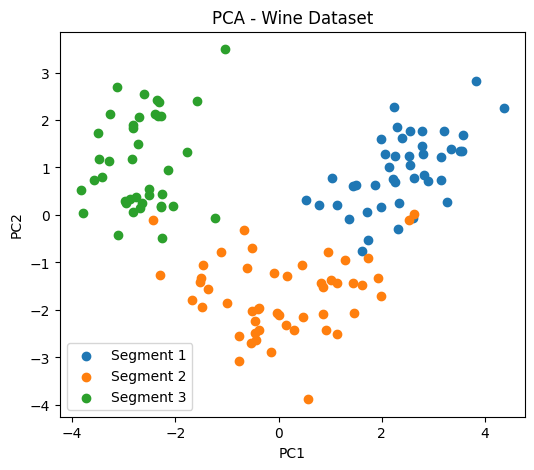

In [9]:
plt.figure(figsize=(6, 5))
for segment in np.unique(Y_train):
  plt.scatter(X_train_pca[Y_train == segment, 0],
              X_train_pca[Y_train == segment, 1],
              label=f'Segment {segment}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA - Wine Dataset')
plt.legend()
plt.show()


In [10]:
from sklearn.linear_model import LogisticRegression
classifier_pca = LogisticRegression(random_state=0)
classifier_pca.fit(X_train_pca, Y_train)
Y_pred_pca = classifier_pca.predict(X_test_pca)

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
cm_pca = confusion_matrix(Y_test, Y_pred_pca)
print("Confusion Matrix (PCA):\n", cm_pca)
print("\nClassification Report (PCA):\n", classification_report(Y_test, Y_pred_pca))

Confusion Matrix (PCA):
 [[16  0  0]
 [ 1 20  0]
 [ 0  0  8]]

Classification Report (PCA):
               precision    recall  f1-score   support

           1       0.94      1.00      0.97        16
           2       1.00      0.95      0.98        21
           3       1.00      1.00      1.00         8

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



**Part 2: Implementing LDA (Linear Discriminant Analysis)**

In [12]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train, Y_train) # LDA needs labels — supervised
X_test_lda = lda.transform(X_test)

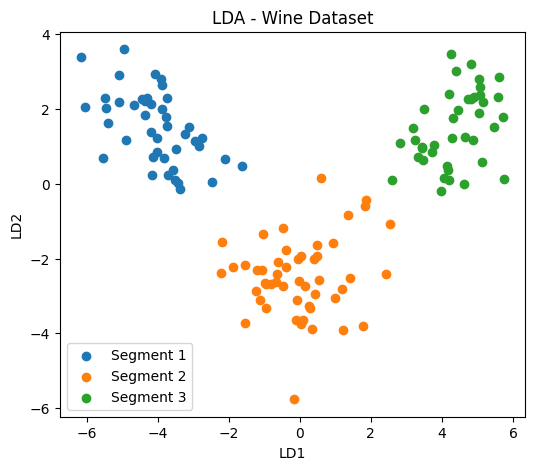

In [13]:
plt.figure(figsize=(6, 5))
for segment in np.unique(Y_train):
  plt.scatter(X_train_lda[Y_train == segment, 0],
              X_train_lda[Y_train == segment, 1],
              label=f'Segment {segment}')

plt.xlabel('LD1')
plt.ylabel('LD2')
plt.title('LDA - Wine Dataset')
plt.legend()
plt.show()

In [14]:
classifier_lda = LogisticRegression(random_state=0)
classifier_lda.fit(X_train_lda, Y_train)
Y_pred_lda = classifier_lda.predict(X_test_lda)
cm_lda = confusion_matrix(Y_test, Y_pred_lda)
print("Confusion Matrix (LDA):\n", cm_lda)
print("\nClassification Report (LDA):\n", classification_report(Y_test, Y_pred_lda))

Confusion Matrix (LDA):
 [[16  0  0]
 [ 0 21  0]
 [ 0  0  8]]

Classification Report (LDA):
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        16
           2       1.00      1.00      1.00        21
           3       1.00      1.00      1.00         8

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

